In [1]:
%% MIT 18.03 Lecture 30: Grand Unification of Poles, Transfer Function & Amplitude Response
% Description: Visualizes the geometric connection between s-plane poles and frequency response:
%              1) 3D Surface of |W(s)| intersected by the imaginary axis plane Re(s) = 0
%                 to extract the Amplitude Response Curve |W(j*omega)|.
%              2) Merging of the two resonant humps (positive & negative omega) as poles move left.
%              3) Higher-order (4th-order) multi-pole system frequency response via Control Toolbox.
%
% % Required Toolboxes:
% %   - Control System Toolbox (tf, freqresp, pole, series).
%
% % MBD Concept Mapping: Demonstrates that Bode magnitude gain |W(jw)| is the cross-section
% %                      of the 3D Laplace transfer surface |W(s)| along the imaginary axis.
% %                      Explains resonant peak sharpness via pole proximity to the jw-axis.


clear; clc; close all;


%% =========================================================================
%% Part 1: 3D Transfer Surface |W(s)| & Imaginary Axis Slice |W(jw)| (Sec [4])
%% =========================================================================
% Standard 2nd-order system: W(s) = wn^2 / (s^2 + 2*zeta*wn*s + wn^2)
wn = 2.0;       % Natural circular frequency (rad/s)
zeta = 0.20;    % Light damping -> poles close to imaginary axis
W_sys = tf(wn^2, [1, 2*zeta*wn, wn^2]);
sys_poles = pole(W_sys);


fprintf('=== MIT 18.03 Lecture 30 Unification Diagnostics ===\n');

=== MIT 18.03 Lecture 30 Unification Diagnostics ===

In [2]:
fprintf('Plant Transfer Function W(s):\n');

Plant Transfer Function W(s):

In [3]:
display(W_sys);

W_sys =
 
         4
  ---------------
  s^2 + 0.8 s + 4
 
Continuous-time transfer function.
Model Properties

In [4]:
fprintf('System Poles : %+.4f %+.4fi, %+.4f %+.4fi\n', ...
        real(sys_poles(1)), imag(sys_poles(1)), real(sys_poles(2)), imag(sys_poles(2)));

System Poles : -0.4000 +1.9596i, -0.4000 -1.9596i


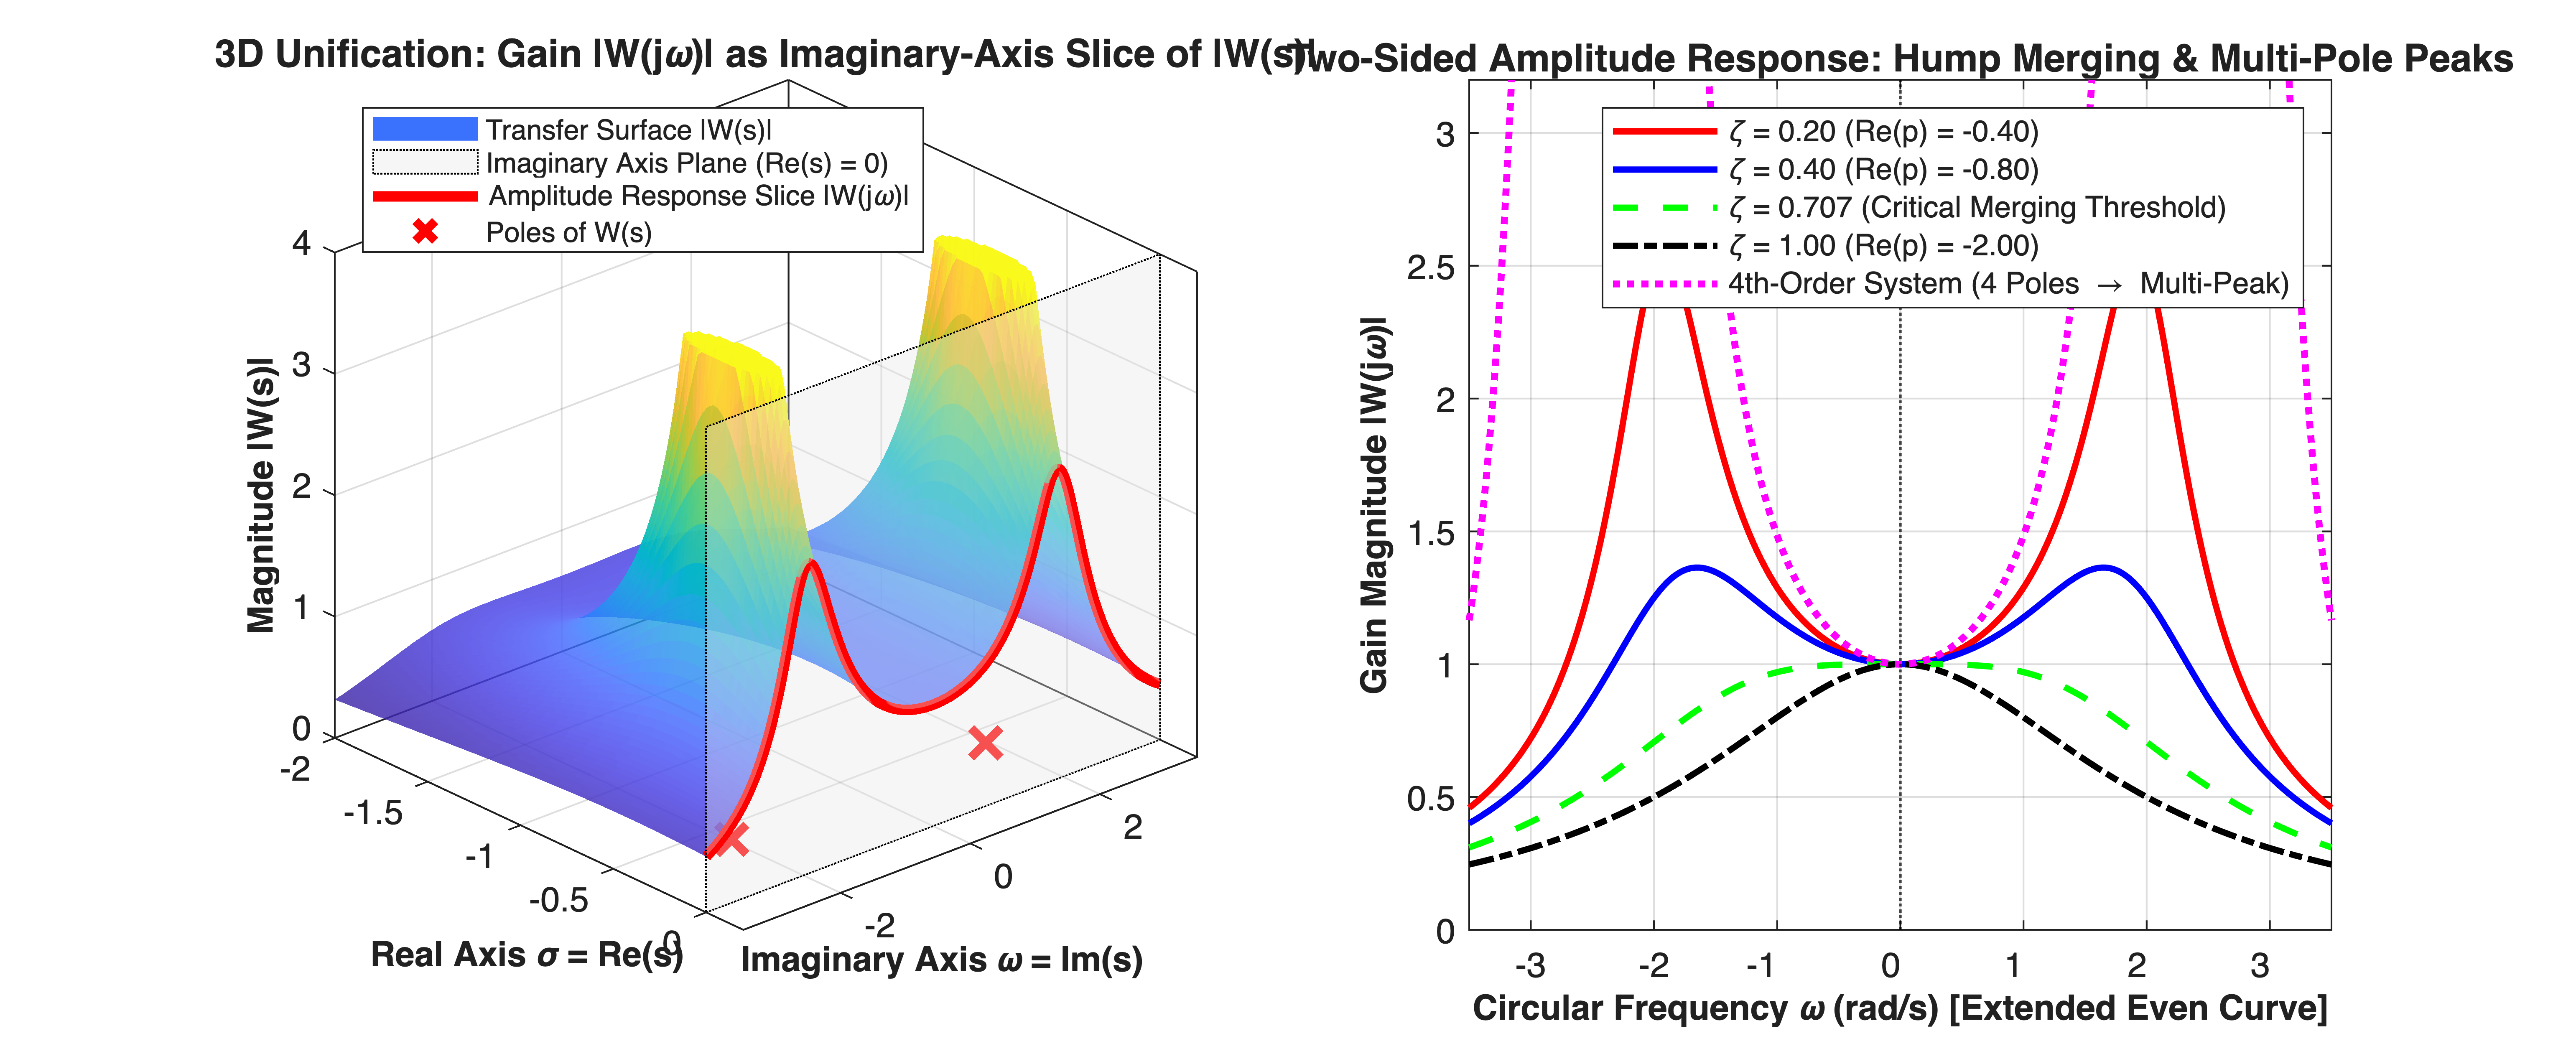

In [5]:


% Evaluate Complex Gain along the imaginary axis using Control System Toolbox 'freqresp'
w_slice_vec = linspace(-3.5, 3.5, 400);
H_jw = squeeze(freqresp(W_sys, w_slice_vec));
gain_jw = abs(H_jw);


% Build complex grid over left-half s-plane: sigma in [-2.0, 0.2], omega in [-3.5, 3.5]
sigma_grid = linspace(-2.0, 0.0, 100);
omega_grid = linspace(-3.5, 3.5, 160);
[Sigma, Omega] = meshgrid(sigma_grid, omega_grid);
S_mat = Sigma + 1i * Omega;


% Compute |W(s)| surface and cap singularities at 4.0 for clean visualization
W_mag_surf = abs((wn^2) ./ (S_mat.^2 + 2*zeta*wn*S_mat + wn^2));
cap_val = 4.0;
W_mag_capped = min(W_mag_surf, cap_val);


figure('Color', [1 1 1], 'Position', [60, 60, 1260, 520]);


% Subplot 1: 3D Surface |W(s)| and the Imaginary Axis Intersection Curve
subplot(1, 2, 1);
surf(Sigma, Omega, W_mag_capped, 'EdgeColor', 'none', 'FaceAlpha', 0.82, ...
     'DisplayName', 'Transfer Surface |W(s)|');
hold on; grid on; box on;
colormap(parula);


% Plot the vertical slicing plane over the imaginary axis (Re(s) = 0)
patch([0, 0, 0, 0], [-3.5, 3.5, 3.5, -3.5], [0, 0, cap_val, cap_val], ...
      [0.9 0.9 0.9], 'FaceAlpha', 0.35, 'EdgeColor', 'k', 'LineStyle', ':', ...
      'DisplayName', 'Imaginary Axis Plane (Re(s) = 0)');


% Plot the intersection curve: Amplitude Response |W(j*omega)|
plot3(zeros(size(w_slice_vec)), w_slice_vec, gain_jw, 'r-', 'LineWidth', 3.0, ...
      'DisplayName', 'Amplitude Response Slice |W(j\omega)|');


% Plot pole locations on base plane
plot3(real(sys_poles), imag(sys_poles), [0; 0], 'rx', 'MarkerSize', 12, ...
      'LineWidth', 2.5, 'DisplayName', 'Poles of W(s)');


xlabel('Real Axis \sigma = Re(s)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('Imaginary Axis \omega = Im(s)', 'FontSize', 10, 'FontWeight', 'bold');
zlabel('Magnitude |W(s)|', 'FontSize', 10, 'FontWeight', 'bold');
title('3D Unification: Gain |W(j\omega)| as Imaginary-Axis Slice of |W(s)|', ...
      'FontSize', 11, 'FontWeight', 'bold');
view([48, 28]);
xlim([-2.0, 0.2]); ylim([-3.5, 3.5]); zlim([0, cap_val]);
legend('Location', 'northwest', 'FontSize', 8);


%% =========================================================================
%% Part 2: Merging of Two Humps with Increasing Damping & Higher-Order Poles
%% =========================================================================
% Lecture Sec [4]: "If you increase the damping, the poles move deeper into
% negative real part space, and eventually the two humps in the frequency response curve merge."
zeta_list = [0.20, 0.40, 1/sqrt(2), 1.0]; % 1/sqrt(2) ~ 0.707 is the exact hump-merging threshold!
colors = {'r-', 'b-', 'g--', 'k-.'};


subplot(1, 2, 2);
hold on; grid on; box on;


for idx = 1:length(zeta_list)
    z_val = zeta_list(idx);
    W_temp = tf(wn^2, [1, 2*z_val*wn, wn^2]);
    g_curve = abs(squeeze(freqresp(W_temp, w_slice_vec)));

    if abs(z_val - 1/sqrt(2)) < 1e-4
        lbl = sprintf('\\zeta = 0.707 (Critical Merging Threshold)');
    else
        lbl = sprintf('\\zeta = %.2f (Re(p) = %.2f)', z_val, -z_val*wn);
    end
    plot(w_slice_vec, g_curve, colors{idx}, 'LineWidth', 1.8, 'DisplayName', lbl);
end


% Overlay a 4th-order system with two pairs of complex poles
W_4th = series(tf(4, [1, 0.4, 4]), tf(9, [1, 0.5, 9])); % Modes near w = 2 and w = 3
g_4th = abs(squeeze(freqresp(W_4th, w_slice_vec)));
plot(w_slice_vec, g_4th, 'm:', 'LineWidth', 2.0, ...
     'DisplayName', '4th-Order System (4 Poles \rightarrow Multi-Peak)');


xline(0, 'k:', 'LineWidth', 0.8, 'HandleVisibility', 'off');
xlabel('Circular Frequency \omega (rad/s) [Extended Even Curve]', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('Gain Magnitude |W(j\omega)|', 'FontSize', 10, 'FontWeight', 'bold');
title('Two-Sided Amplitude Response: Hump Merging & Multi-Pole Peaks', ...
      'FontSize', 11, 'FontWeight', 'bold');
legend('Location', 'northeast', 'FontSize', 8.5);
xlim([-3.5, 3.5]);
ylim([0, 3.2]);

In [6]:


fprintf('Two-Hump Merging Condition: Resonant peaks at +/- wr merge at w = 0 when zeta >= 1/sqrt(2) = 0.7071.\n');

Two-Hump Merging Condition: Resonant peaks at +/- wr merge at w = 0 when zeta >= 1/sqrt(2) = 0.7071.

In [7]:
fprintf('====================================================\n');